# 4. Preparação da Base Cartográfica dos Municípios 

## 4.1 Introdução

Este notebook realiza a preparação da base cartográfica dos municípios que compõem a área de estudo da Bacia Hidrográfica do Rio Doce. A partir da malha municipal do IBGE e do limite da bacia previamente preparado, são executadas as etapas de carregamento, inspeção, recorte espacial, visualização e exportação dos municípios pertencentes à área de estudo, gerando uma camada vetorial que será utilizada nas análises territoriais e ambientais das próximas etapas do projeto.

## 4.2 Objetivos

Ao final deste notebook será possível:

- carregar a malha municipal do Brasil;
- verificar a consistência dos dados vetoriais;
- recortar os municípios utilizando o limite da Bacia do Rio Doce;
- identificar os municípios pertencentes à área de estudo;
- visualizar os resultados do processamento;
- exportar a camada vetorial para utilização nas próximas etapas do projeto.

## 4.3 Bibliotecas

In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

## 4.4 Estrutura dos Diretórios

In [2]:
def encontrar_raiz_projeto(marcador=".git"):
    """Localiza a raiz do projeto a partir do diretório atual ou de seus pais."""
    caminho = Path.cwd().resolve()

    for pasta in (caminho, *caminho.parents):
        if (pasta / marcador).exists():
            return pasta

    raise FileNotFoundError(
        "Diretório raiz do projeto não encontrado. "
        "Verifique se o notebook está sendo executado dentro do repositório."
    )


ROOT = encontrar_raiz_projeto()
print(f"Raiz do projeto: {ROOT}")

Raiz do projeto: C:\Users\claud\Documents\Python_GIS\Bacia_Rio_Doce


In [3]:
DIR_DADOS = ROOT / "dados"

DIR_BRUTOS = DIR_DADOS / "brutos"
DIR_PROCESSADOS = DIR_DADOS / "processados"

DIR_ANA = DIR_BRUTOS / "ANA"
DIR_IBGE = DIR_BRUTOS / "IBGE"

DIR_MUNICIPIOS = DIR_PROCESSADOS / "municipios"
DIR_AREA = DIR_PROCESSADOS / "area_estudo"

# Garante que a pasta de saída exista.
DIR_MUNICIPIOS.mkdir(parents=True, exist_ok=True)

## 4.5 Dados de entrada

Arquivos utilizados

- IBGE/municipios.gpkg
- bacia_rio_doce.gpkg

Fontes

- Instituto Brasileiro de Geografia e Estatística (IBGE)
- Agência Nacional de Águas e Saneamento Básico (ANA)

Formatos

- GeoPackage (GPKG)

Sistema de referência esperado

- Municípios: EPSG:4674 (SIRGAS 2000)
- Área de estudo: EPSG:4674 (SIRGAS 2000)

## 4.6 Leitura

### Municípios

In [4]:
INPUT_IBGE = DIR_IBGE / "municipios.gpkg"

if not INPUT_IBGE.is_file():
    raise FileNotFoundError(
        f"Arquivo de entrada não encontrado: {INPUT_IBGE.relative_to(ROOT)}"
    )

municipios = gpd.read_file(INPUT_IBGE)
print(f"Arquivo carregado: {INPUT_IBGE.relative_to(ROOT)}")

C:\Users\claud\anaconda3\envs\AmbGEO\Lib\site-packages\pyogrio\core.py:34: RuntimeWarning: Could not detect GDAL data files. Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


Arquivo carregado: dados\brutos\IBGE\municipios.gpkg


### Área de estudo

In [5]:
INPUT_AREA = DIR_AREA / "bacia_rio_doce.gpkg"

if not INPUT_AREA.is_file():
    raise FileNotFoundError(
        f"Arquivo de entrada não encontrado: {INPUT_AREA.relative_to(ROOT)}"
    )

bacia_rio_doce = gpd.read_file(INPUT_AREA)
print(f"Arquivo carregado: {INPUT_AREA.relative_to(ROOT)}")

Arquivo carregado: dados\processados\area_estudo\bacia_rio_doce.gpkg


## 4.7 Exploração

### Municípios

In [6]:
municipios.head()

,CD_MUN,NM_MUN,CD_RGI,NM_RGI,CD_RGINT,NM_RGINT,CD_UF,NM_UF,SIGLA_UF,CD_REGIAO,NM_REGIAO,SIGLA_RG,CD_CONCURB,NM_CONCURB,AREA_KM2,geometry
0,2410900,Riachuelo,240006,São Paulo do Potengi,2401,Natal,24,Rio Grande do Norte,RN,2,Nordeste,NE,NaN,NaN,262.880,"MULTIPOLYGON (((-35.78413 -5.82524, -35.79682 ..."
1,4202438,Bocaina do Sul,420005,Lages,4203,Lages,42,Santa Catarina,SC,4,Sul,S,NaN,NaN,510.673,"MULTIPOLYGON (((-49.91152 -27.85242, -49.91152..."
2,4316204,Rondinha,430028,Carazinho,4306,Passo Fundo,43,Rio Grande do Sul,RS,4,Sul,S,NaN,NaN,252.454,"MULTIPOLYGON (((-52.77871 -27.85295, -52.76015..."
3,3118205,Conquista,310055,Uberaba,3110,Uberaba,31,Minas Gerais,MG,3,Sudeste,SE,NaN,NaN,618.363,"MULTIPOLYGON (((-47.59239 -20.00701, -47.59398..."
4,3110806,Campanário,310013,Teófilo Otoni,3103,Teófilo Otoni,31,Minas Gerais,MG,3,Sudeste,SE,NaN,NaN,442.398,"MULTIPOLYGON (((-41.80297 -18.41975, -41.80291..."


In [7]:
print("Malha municipal")
print("-"*40)
print(f"Municípios : {len(municipios):,}")
print(f"CRS        : {municipios.crs}")
print(f"Geometria  : {municipios.geom_type.value_counts()}")
print(f"Geometrias válidas: {municipios.is_valid.sum()} de {len(municipios)}")

Malha municipal
----------------------------------------
Municípios : 5,572
CRS        : EPSG:4674
Geometria  : MultiPolygon    5572
Name: count, dtype: int64
Geometrias válidas: 5572 de 5572


In [8]:
municipios.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   CD_MUN      5572 non-null   str     
 1   NM_MUN      5572 non-null   str     
 2   CD_RGI      5570 non-null   str     
 3   NM_RGI      5570 non-null   str     
 4   CD_RGINT    5570 non-null   str     
 5   NM_RGINT    5570 non-null   str     
 6   CD_UF       5572 non-null   str     
 7   NM_UF       5572 non-null   str     
 8   SIGLA_UF    5572 non-null   str     
 9   CD_REGIAO   5572 non-null   str     
 10  NM_REGIAO   5572 non-null   str     
 11  SIGLA_RG    5572 non-null   str     
 12  CD_CONCURB  660 non-null    str     
 13  NM_CONCURB  660 non-null    str     
 14  AREA_KM2    5572 non-null   float64 
 15  geometry    5572 non-null   geometry
dtypes: float64(1), geometry(1), str(14)
memory usage: 1.1 MB


## 4.8 Processamento

### Recorte espacial

In [9]:
print(f"CRS Municípios: {municipios.crs}")
print(f"CRS Bacia     : {bacia_rio_doce.crs}")       

CRS Municípios: EPSG:4674
CRS Bacia     : EPSG:4674


In [10]:
municipios_rio_doce = gpd.clip(
    municipios,
    bacia_rio_doce
)

O **clip()** recorta as geometrias municipais pelo limite da Bacia do Rio Doce. Dessa forma, municípios que atravessam o limite da bacia têm suas geometrias reduzidas à porção localizada dentro da área de estudo.

In [11]:
municipios_rio_doce.head()

,CD_MUN,NM_MUN,CD_RGI,NM_RGI,CD_RGINT,NM_RGINT,CD_UF,NM_UF,SIGLA_UF,CD_REGIAO,NM_REGIAO,SIGLA_RG,CD_CONCURB,NM_CONCURB,AREA_KM2,geometry
3442,3105608,Barbacena,310037,Barbacena,3107,Barbacena,31,Minas Gerais,MG,3,Sudeste,SE,3105608,Barbacena/MG,759.186,"MULTIPOLYGON (((-43.60828 -21.13116, -43.60833..."
672,3101631,Alfredo Vasconcelos,310037,Barbacena,3107,Barbacena,31,Minas Gerais,MG,3,Sudeste,SE,3105608,Barbacena/MG,130.815,"MULTIPOLYGON (((-43.65945 -21.09198, -43.6592 ..."
3624,3154408,Ressaquinha,310037,Barbacena,3107,Barbacena,31,Minas Gerais,MG,3,Sudeste,SE,NaN,NaN,183.062,"POLYGON ((-43.72252 -21.03243, -43.72252 -21.0..."
1119,3166204,Senhora dos Remédios,310037,Barbacena,3107,Barbacena,31,Minas Gerais,MG,3,Sudeste,SE,NaN,NaN,237.815,"POLYGON ((-43.52205 -21.03411, -43.52212 -21.0..."
3489,3113206,Carandaí,310038,Conselheiro Lafaiete,3107,Barbacena,31,Minas Gerais,MG,3,Sudeste,SE,NaN,NaN,487.280,"MULTIPOLYGON (((-43.79803 -20.88308, -43.79788..."


### Validação dos resultados após o recorte

In [12]:
print(f"Número de feições depois do recorte: {len(municipios_rio_doce):}")
print(f"CRS: {municipios_rio_doce.crs}")
print(f"Geometria das feições depois do recorte:") 
print(municipios_rio_doce.geom_type.value_counts())
print(f"Municípios por Estado:") 
print(municipios_rio_doce["SIGLA_UF"].value_counts())
print(f"Geometrias válidas: {municipios_rio_doce.is_valid.sum()} de {len(municipios_rio_doce)}")

Número de feições depois do recorte: 272
CRS: EPSG:4674
Geometria das feições depois do recorte:
Polygon         207
MultiPolygon     65
Name: count, dtype: int64
Municípios por Estado:
SIGLA_UF
MG    235
ES     37
Name: count, dtype: int64
Geometrias válidas: 272 de 272


### Cálculo da área das porções municipais dentro da bacia

In [13]:
municipios_rio_doce_utm = municipios_rio_doce.to_crs("EPSG:10857")

municipios_rio_doce["AREA_KM2_BACIA"] = (
    municipios_rio_doce_utm.geometry.area / 1_000_000
)
municipios_rio_doce[["AREA_KM2", "AREA_KM2_BACIA"]].head()

,AREA_KM2,AREA_KM2_BACIA
3442,759.186,0.363426
672,130.815,0.706840
3624,183.062,44.730459
1119,237.815,237.787469
3489,487.280,43.027275


### Validação da área da bacia

In [14]:
area_bacia_corte = municipios_rio_doce_utm.geometry.area.sum() / 1_000_000

print(f"Área da Bacia do Rio Doce a partir das geometrias municipais: {area_bacia_corte:,.2f} km²")

Área da Bacia do Rio Doce a partir das geometrias municipais: 86,052.95 km²


**Validação da área**: a soma das áreas das geometrias municipais após o recorte resultou em 86.052,95 km², enquanto a área da Bacia do Rio Doce calculada no Notebook 1 foi de 86.093,32 km². A diferença de 40,37 km² corresponde a aproximadamente 0,05% da área da bacia. A pequena diferença **pode** estar relacionada às características e precisão das geometrias utilizadas nas diferentes camadas. O resultado é considerado consistente para fins desta etapa.

## 4.9 Visualização

### Bacia do Rio Doce sobre Municípios do Brasil

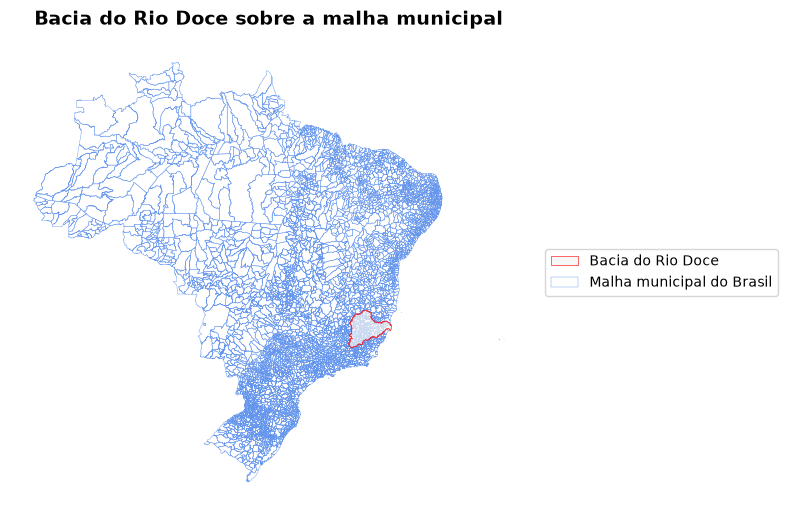

In [15]:
fig, ax = plt.subplots(figsize=(8, 8))

# Área da bacia
bacia_rio_doce.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="red",
    linewidth=0.6,
    alpha=0.7,
    label="Bacia do Rio Doce",
    zorder=2
)

# malha municipal
municipios.plot(
    ax=ax,
    facecolor="none",
    edgecolor="cornflowerblue",
    linewidth=0.3,
    label="Malha municipal do Brasil",
    zorder=1
)

ax.set_title(
    "Bacia do Rio Doce sobre a malha municipal",
    fontsize=14,
    fontweight="bold",
    pad=12
)

# Remove os eixos
ax.set_axis_off()

# Legenda fora do mapa
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=True
)

plt.tight_layout()
plt.show()

### Bacia Recortada

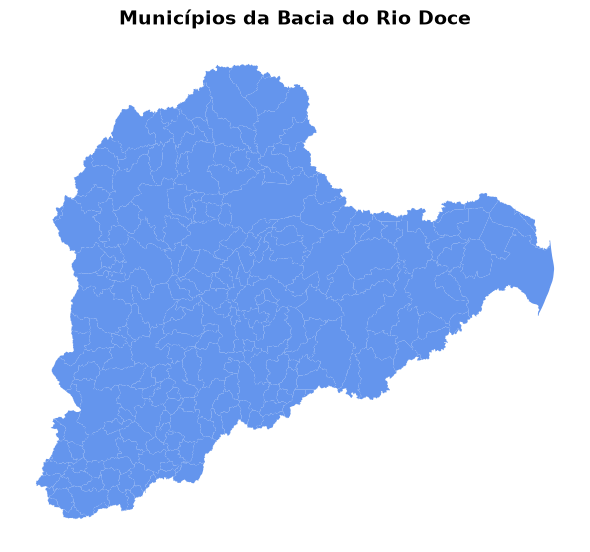

In [16]:
fig, ax = plt.subplots(figsize=(6, 6))

municipios_rio_doce.plot(
    ax=ax,
    color="cornflowerblue",
    linewidth=0.5
)

ax.set_title(
    "Municípios da Bacia do Rio Doce",
    fontsize=14,
    fontweight="bold",
    pad=12
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 4.10 Exportação e salvamento

In [17]:
OUTPUT_MUNICIPIOS = DIR_MUNICIPIOS / "municipios_rio_doce.gpkg"

municipios_rio_doce.to_file(
    OUTPUT_MUNICIPIOS,
    driver="GPKG"
)


print(f"Caminho de saída: {OUTPUT_MUNICIPIOS.relative_to(ROOT)}")

Caminho de saída: dados\processados\municipios\municipios_rio_doce.gpkg


A utilização de uma camada vetorial contendo apenas os municípios da área de estudo reduz o volume de dados processados e garante que todas as análises subsequentes estejam espacialmente consistentes com o limite da bacia.

### Verificar o arquivo gerado

In [18]:
municipios_verificacao = gpd.read_file(OUTPUT_MUNICIPIOS)

print("CRS:", municipios_verificacao.crs)
print("Feições:", len(municipios_verificacao))
print("Geometria:", municipios_verificacao.geom_type.unique())

CRS: EPSG:4674
Feições: 272
Geometria: <ArrowStringArray>
['MultiPolygon']
Length: 1, dtype: str


## 4.11 Conclusão

Neste notebook foi preparada a base cartográfica dos municípios pertencentes à Bacia Hidrográfica do Rio Doce. A malha municipal foi carregada, inspecionada e recortada utilizando o limite da área de estudo, resultando em uma camada vetorial contendo as porções dos municípios localizadas dentro da Bacia do Rio Doce. Esta camada será utilizada nas análises territoriais, ambientais e socioeconômicas das próximas etapas do projeto.               